In [ ]:
import os
import pandas as pd
from sklearn.metrics import f1_score
from sklearn.preprocessing import LabelEncoder
from pathlib import Path
import numpy as np

In [15]:
ICL_RESULTS_PATH = Path("/storage2/albert/iSTS-mgr/results/icl")

type_task_path = ICL_RESULTS_PATH / "alignment"

results = []

for model in os.listdir(type_task_path):
    for scenario in os.listdir(type_task_path / model):
        df = pd.read_csv(type_task_path / model / scenario /"results.csv")
        le = LabelEncoder()
        all_values = df.alignment.tolist() + df.preds.tolist()
        le.fit(all_values)
        y_true = le.transform(df.alignment)
        y_pred = le.transform(df.preds)

        scenario_config = scenario.split("_")
        scenario_config = [item for item in scenario_config if (not item.isdigit() or len(item) == 1) and item != "score"]
        score = f1_score(y_true, y_pred, average="weighted")
        # print(f"{model}, {scenario}, score:", score)

        results.append(
            {"model": model,
            "dataset": scenario_config[0],
            "instruction": scenario_config[1],
            "n_examples": scenario_config[2],
            "score": score}
        )

In [17]:
df_results_type = pd.DataFrame(results)
df_results_type['instruction'].unique()

array(['simple', 'detailed'], dtype=object)

In [18]:
df_results_type.to_csv("type_results.csv")

In [81]:
df_score = pd.read_csv("/storage2/albert/iSTS-mgr/src/notebooks/score_results.csv")

In [74]:
df_score[df_score["model"] == "Llama-3.1-8B-Instruct"]["score"]

0.6704311993650922

In [86]:
dataset_df = df_score[df_score["dataset"] == "images"]
dataset_df.loc[dataset_df["score"].idxmax()]


Unnamed: 0                      46
model          Qwen2.5-7B-Instruct
dataset                     images
instruction               detailed
n_examples                       3
score                     0.831854
Name: 46, dtype: object

In [12]:
df = pd.read_csv("/storage2/albert/iSTS-mgr/src/notebooks/type_results.csv")
df['instruction'].unique()

array(['simple', 'detailed', '003622', '003420', '004232', '010158',
       '010243', '010603', '003528', '010057', '004734', '010534',
       '003923', '010800', '010423', '010355'], dtype=object)

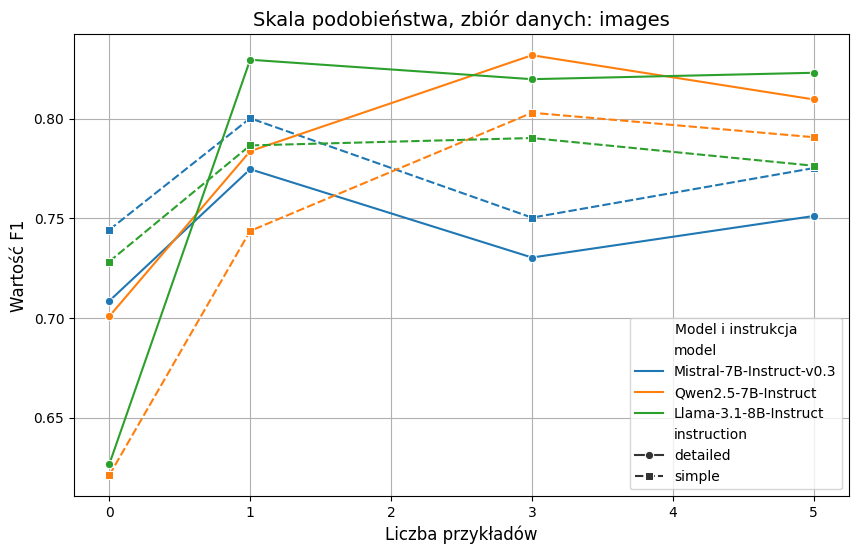

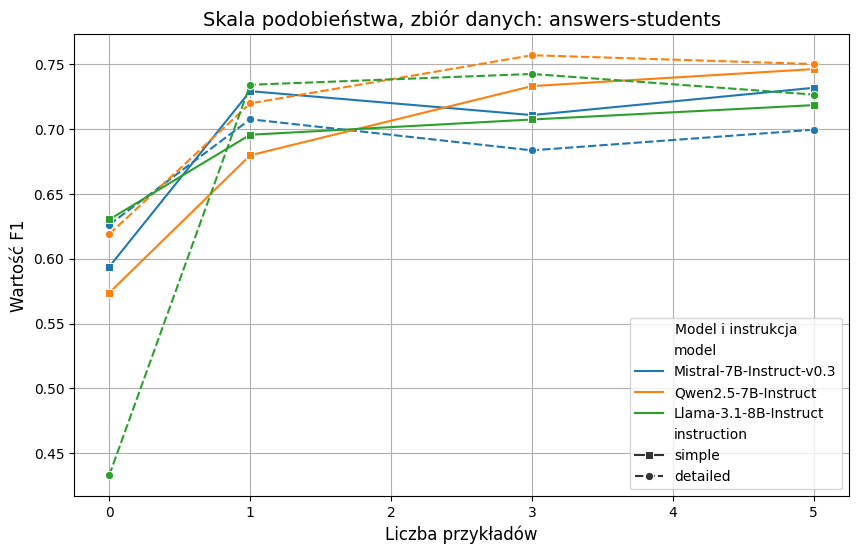

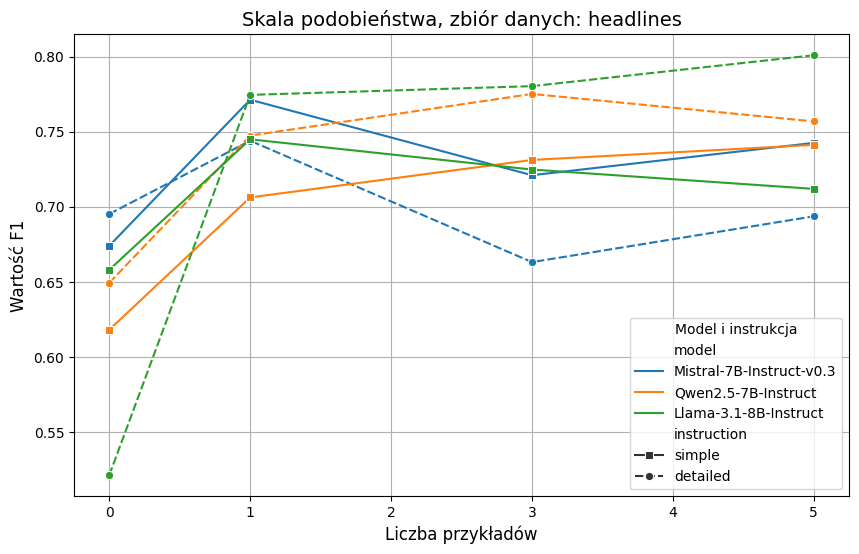

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


df = pd.read_csv("/storage2/albert/iSTS-mgr/src/notebooks/score_results.csv")
# Create plots
datasets = df['dataset'].unique()

instruction_styles = {
    'detailed': 'o',  # Type 1 will always have circles
    'simple': 's'   # Type 2 will always have squares
}
for dataset in datasets:
    # Filter data for the current dataset
    subset = df[df['dataset'] == dataset]
    
    plt.figure(figsize=(10, 6))
    
    # Plot line for each combination of model and instruction
    sns.lineplot(
        data=subset,
        x='n_examples',
        y='score',
        hue='model',
        style='instruction',
        markers=instruction_styles,
    )
    
    # Customize the plot
    plt.title(f'Skala podobieństwa, zbiór danych: {dataset}', fontsize=14)
    plt.xlabel('Liczba przykładów', fontsize=12)
    plt.ylabel('Wartość F1', fontsize=12)
    plt.legend(title='Model i instrukcja', loc='best')
    plt.grid(True)
    
    # Show the plot
    plt.show()


In [20]:
average_scores = df[df['n_examples']==0].groupby(['model', 'instruction'])['score'].mean().reset_index()
# average_scores = df.groupby(['dataset', 'instruction'])['score'].mean().reset_index()
# Output the result
print(average_scores)

                      model instruction     score
0     Llama-3.1-8B-Instruct    detailed  0.734075
1     Llama-3.1-8B-Instruct      simple  0.509908
2  Mistral-7B-Instruct-v0.3    detailed  0.748946
3  Mistral-7B-Instruct-v0.3      simple  0.660074
4       Qwen2.5-7B-Instruct    detailed  0.702034
5       Qwen2.5-7B-Instruct      simple  0.607602


In [ ]:
                      model instruction     score
0     Llama-3.1-8B-Instruct    detailed  0.717709
1     Llama-3.1-8B-Instruct      simple  0.722777
2  Mistral-7B-Instruct-v0.3    detailed  0.706495
3  Mistral-7B-Instruct-v0.3      simple  0.728736
4       Qwen2.5-7B-Instruct    detailed  0.741744
5       Qwen2.5-7B-Instruct      simple  0.707372

In [5]:
import pandas as pd
from sklearn.metrics import accuracy_score

# res = pd.read_csv("/home/a.scisel/2024/llm2vec/iSTS-mgr/results/finetuning/score/0e9e39f249a16976918f6564b8830bc894c89659/headlines_simple_0_20250429_155824/results.csv")
res = pd.read_csv("/home/a.scisel/2024/llm2vec/iSTS-mgr/results/finetuning/alignment/a09a35458c702b33eeacc393d103063234e8bc28/20250525_194810/headlines_simple_0_20250525_202618/results.csv")


In [7]:
res

,text_source,text_translation,alignment,score,preds,response
0,for the Philippines,to Philippines,EQUI,5,EQUI,Label: EQUI
1,departs,sends,SIMI,3,EQUI,Label: EQUI
2,Thursday,-not aligned-,NOALI,0,NOALI,Label: NOALI
3,China,China,EQUI,5,EQUI,Label: EQUI
4,'s Peace Ark,aid team,REL,4,SPE2,Label: SPE2
...,...,...,...,...,...,...
2035,Most victims,38 bodies of victims,SPE2,3,EQUI,Label: EQUI
2036,identified,identified,EQUI,5,EQUI,Label: EQUI
2037,in blast,in apartment blast,SPE2,4,EQUI,Label: EQUI
2038,hurt,injured,EQUI,5,EQUI,Label: EQUI


In [8]:
true_label, preds = res['alignment'], res['preds']

accuracy_score(true_label, preds)

TypeError: '<' not supported between instances of 'float' and 'str'

## F1 results analysis

In [3]:
import pandas as pd

df_penalty = pd.read_csv("/data/home/ascisel/open_webui/iSTS-mgr/results_new/processed/evalF1_penalty/all_f1_results.csv")
df_no_penalty = pd.read_csv("/data/home/ascisel/open_webui/iSTS-mgr/results_new/processed/evalF1_no_penalty/all_f1_results.csv")
df_penalty["run_type"] = df_penalty["run_type"].fillna("separated").replace({"paired": "separated"})
df_no_penalty["run_type"] = df_no_penalty["run_type"].fillna("separated").replace({"paired": "separated"})

In [20]:
import re
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


def create_plots(df, metric, label, df_name):

# Only ICL
    df = df[df["method"] == "icl"].copy()

    df = df[df["run_type"] == label]

    df = df_penalty[df_penalty["method"] == "icl"].copy()

    # Cleanup
    df["idx"] = pd.to_numeric(df["idx"], errors="coerce")
    df[metric] = pd.to_numeric(df[metric], errors="coerce")
    df = df.dropna(subset=["dataset", "model", "desc", "idx", metric])
    df = df.sort_values(["dataset", "model", "desc", "idx"])

    instruction_styles = {"detailed": "o", "simple": "s"}

    # Output dir
    OUTDIR = Path(f"/data/home/ascisel/open_webui/iSTS-mgr/results/figures/f1_icl2/{"penalty" if df_name == "penalty" else "no_penalty"}")
    OUTDIR.mkdir(parents=True, exist_ok=True)

    def safe_name(s: str) -> str:
        return re.sub(r"[^A-Za-z0-9_.-]+", "_", str(s)).strip("_")

    datasets = sorted(df["dataset"].unique())

    for dataset in datasets:
        subset = df[df["dataset"] == dataset]

        plt.figure(figsize=(10, 6))
        ax = sns.lineplot(
            data=subset,
            x="idx",
            y=metric,
            hue="model",
            style="desc",
            markers=instruction_styles,
            dashes=False,
            linewidth=2,
            errorbar=None
        )

        ax.set_title(f"F1 ({metric} {df_name}) — zbiór danych: {dataset}, etykieta: {label}", fontsize=14)
        ax.set_xlabel("Liczba przykładów uczących w prompcie", fontsize=12)
        ax.set_ylabel("Wartość F1", fontsize=12)
        ax.grid(True, alpha=0.3)
        ax.legend(title="Model / instrukcja", loc="best")

        plt.tight_layout()
        print("siema")
        stem = f"icl_{safe_name(dataset)}_{safe_name(metric)}_eval_{df_name}_{label}"
        plt.savefig(OUTDIR / f"{stem}.png", dpi=300)
        plt.savefig(OUTDIR / f"{stem}.pdf")
        plt.close()


In [21]:
METRICS = ["f1_typescore"]
LABELS = ["separated", "both", "merged"]

for metric in METRICS:
    for label in LABELS:
        create_plots(df_penalty, metric, label, "penalty")

siema
siema
siema
siema
siema
siema
siema
siema
siema


In [22]:
METRICS = ["f1_typescore"]
LABELS = ["separated", "both", "merged"]

for metric in METRICS:
    for label in LABELS:
        create_plots(df_no_penalty, metric, label, "no penalty")

siema
siema
siema
siema
siema
siema
siema
siema
siema


In [48]:

# jeśli masz inną nazwę kolumny:
if "f1_scoretype" in df.columns and "f1_typescore" not in df.columns:
    df = df.rename(columns={"f1_scoretype": "f1_typescore"})

df["f1_typescore"] = pd.to_numeric(df["f1_typescore"], errors="coerce")

mean_per_dataset = (
    df.groupby("dataset", as_index=False)["f1_typescore"]
      .mean()
      .rename(columns={"f1_typescore": "mean_f1_typescore"})
      .sort_values("mean_f1_typescore", ascending=False)
)

print(mean_per_dataset)

            dataset  mean_f1_typescore
1         headlines           0.642369
2            images           0.587453
0  answers-students           0.572503


In [49]:
if "f1_scoretype" in df.columns and "f1_typescore" not in df.columns:
    df = df.rename(columns={"f1_scoretype": "f1_typescore"})

df["f1_typescore"] = pd.to_numeric(df["f1_typescore"], errors="coerce")
df["idx"] = pd.to_numeric(df["idx"], errors="coerce")

# exclude rows where method == ICL and idx == 0
mask_exclude = (df["method"] == "icl") & (df["idx"] == 0)
df_filt = df[~mask_exclude].copy()

mean_per_dataset = (
    df_filt.groupby("dataset", as_index=False)["f1_typescore"]
           .mean()
           .rename(columns={"f1_typescore": "mean_f1_typescore"})
           .sort_values("mean_f1_typescore", ascending=False)
)

print(mean_per_dataset)

            dataset  mean_f1_typescore
1         headlines           0.669588
0  answers-students           0.613346
2            images           0.609838


In [53]:
df = pd.read_csv("/data/home/ascisel/open_webui/iSTS-mgr/results/processed/evalF1_penalty/all_f1_results.csv")

if "f1_scoretype" in df.columns and "f1_typescore" not in df.columns:
    df = df.rename(columns={"f1_scoretype": "f1_typescore"})

# only finetuning
ft = df[df["method"] == "finetuning"].copy()

# numeric
for c in ["f1_type", "f1_score", "f1_typescore"]:
    ft[c] = pd.to_numeric(ft[c], errors="coerce")

# mean per model (across all rows / datasets / scenarios)
per_model_means = (
    ft.groupby("model", as_index=False)[["f1_type", "f1_score", "f1_typescore"]]
      .mean()
      .rename(columns={
          "f1_type": "mean_f1_type",
          "f1_score": "mean_f1_score",
          "f1_typescore": "mean_f1_typescore",
      })
      .sort_values("mean_f1_typescore", ascending=False)
)

print(per_model_means)

                      model  mean_f1_type  mean_f1_score  mean_f1_typescore
1  Mistral-7B-Instruct-v0.3      0.734333       0.935100           0.784067
0     Llama-3.1-8B-Instruct      0.591767       0.884133           0.698600
2       Qwen2.5-7B-Instruct      0.573033       0.847900           0.672567


## MEAN TOKENS

In [1]:
import pandas as pd

In [2]:
df_tokens = pd.read_csv("/data/home/ascisel/open_webui/iSTS-mgr/results_new/mean_tokens_summary.csv")

In [4]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt


SUMMARY_CSV = Path("/data/home/ascisel/open_webui/iSTS-mgr/results_new/mean_tokens_summary.csv")
OUTDIR = Path("/data/home/ascisel/open_webui/iSTS-mgr/results/figures/mean_tokens")
OUTDIR.mkdir(parents=True, exist_ok=True)


def barplot_mean_tokens(df: pd.DataFrame, method: str, top_n: int, out_name: str, color:str = "steelblue"):
    d = df[df["method"] == method].copy()
    d["mean_tokens"] = pd.to_numeric(d["mean_tokens"], errors="coerce")
    d = d.dropna(subset=["mean_tokens"])

    if d.empty:
        print(f"No data for method={method}")
        return

    # pick top-N models by number of scenarios (rows)
    top_models = d["model"].value_counts().head(top_n).index.tolist()
    d = d[d["model"].isin(top_models)]

    agg = (d.groupby("model", as_index=False)
             .agg(mean_tokens=("mean_tokens", "mean"), n=("mean_tokens", "size"))
             .sort_values("mean_tokens", ascending=False))

    fig, ax = plt.subplots(figsize=(4.0, 5.0))
    ax.bar(agg["model"], agg["mean_tokens"], color=color)  # default colors, clean look

    # ax.set_title(f"Mean response length (tokens) — {method}")
    ax.set_ylabel("Średnia liczba wygenerowanych tokenów")
    ax.set_xlabel("Model", loc="center")
    ax.grid(True, axis="y", alpha=0.3)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    # add values on top of bars (optional, but nice)
    for i, row in agg.reset_index(drop=True).iterrows():
        ax.text(i, row["mean_tokens"], f"{row['mean_tokens']:.1f}", ha="center", va="bottom", fontsize=9)

    plt.xticks(rotation=20, ha="right")
    import matplotlib.transforms as mtransforms

    dx_pts = 30  # move right by 4 points (try 2–8)
    offset = mtransforms.ScaledTranslation(dx_pts/72, 0, fig.dpi_scale_trans)

    for lab in ax.get_xticklabels():
        lab.set_transform(lab.get_transform() + offset)
    plt.tight_layout()

    fig.savefig(OUTDIR / f"{out_name}.pdf")
    fig.savefig(OUTDIR / f"{out_name}.png", dpi=300)
    plt.close(fig)

    print(f"Saved: {OUTDIR / (out_name + '.pdf')}")


  


In [5]:

barplot_mean_tokens(df_tokens, method="icl", top_n=4, out_name="mean_tokens_icl_4models")
barplot_mean_tokens(df_tokens, method="finetuning", top_n=3, out_name="mean_tokens_finetuning_3models", color="darkorange")


Saved: /data/home/ascisel/open_webui/iSTS-mgr/results/figures/mean_tokens/mean_tokens_icl_4models.pdf
Saved: /data/home/ascisel/open_webui/iSTS-mgr/results/figures/mean_tokens/mean_tokens_finetuning_3models.pdf


In [6]:
barplot_mean_tokens(df_tokens[df_tokens["desc"]=="simple"], method="icl", top_n=4, out_name="mean_tokens_icl_4models_simple", color="steelblue")
barplot_mean_tokens(df_tokens[df_tokens["desc"]=="detailed"], method="icl", top_n=4, out_name="mean_tokens_icl_4models_detailed", color="indigo")
# barplot_mean_tokens(df_tokens, method="finetuning", top_n=3, out_name="mean_tokens_finetuning_3models", color="darkorange")

Saved: /data/home/ascisel/open_webui/iSTS-mgr/results/figures/mean_tokens/mean_tokens_icl_4models_simple.pdf
Saved: /data/home/ascisel/open_webui/iSTS-mgr/results/figures/mean_tokens/mean_tokens_icl_4models_detailed.pdf


In [11]:
df_nans["task"].value_counts()

task
score        184
alignment    178
both         177
merged       177
Name: count, dtype: int64

In [ ]:
df_nans = df_tokens.copy()
df_nans["n_examples"] = df_nans["idx"]
df_nans["task"] = df_nans["side"]
df_nans["n_examples"] = pd.to_numeric(df_nans["idx"], errors="coerce").astype("Int64")
print(df_nans[["method", "task", "desc", "model", "dataset", "n_examples", "n_nans"]].sort_values(by="n_nans")[-31:].to_latex(index=False))

\begin{tabular}{lllllrr}
\toprule
method & task & desc & model & dataset & n_examples & n_nans \\
\midrule
icl & merged & simple & Qwen2.5-7B-Instruct & answers-students & 1 & 244 \\
icl & merged & detailed & Llama-3.1-8B-Instruct & headlines & 5 & 270 \\
icl & merged & simple & Qwen2.5-7B-Instruct & headlines & 3 & 275 \\
icl & merged & detailed & Llama-3.1-8B-Instruct & headlines & 1 & 287 \\
icl & merged & simple & gpt-oss-120b & headlines & 1 & 288 \\
icl & merged & detailed & Qwen2.5-7B-Instruct & headlines & 3 & 330 \\
icl & both & detailed & Llama-3.1-8B-Instruct & images & 0 & 357 \\
icl & merged & detailed & Qwen2.5-7B-Instruct & headlines & 5 & 362 \\
icl & merged & detailed & Mistral-7B-Instruct-v0.3 & images & 1 & 384 \\
icl & merged & simple & Mistral-7B-Instruct-v0.3 & images & 3 & 405 \\
icl & merged & simple & gpt-oss-120b & images & 5 & 541 \\
icl & merged & simple & Qwen2.5-7B-Instruct & answers-students & 3 & 544 \\
icl & merged & detailed & Qwen2.5-7B-Instruct & ans

In [19]:
abc = pd.read_csv("/data/home/ascisel/open_webui/iSTS-mgr/results_new/icl/merged/Llama-3.1-8B-Instruct/answers-students_detailed_1_20260124_115101/results.csv")
abc["preds"].isna().sum()

np.int64(199)

## Dataset

In [1]:
import os
os.chdir(r"/data/home/ascisel/open_webui/iSTS-mgr")
from src.data.data import get_dataframe

dataframes = ["answers-students", "images", "headlines"]

data = []

for dataframe in dataframes:
    df_test_wa = get_dataframe(dataframe, "test", "wa")
    df_train_wa = get_dataframe(dataframe, "train", "wa")
    data.append((dataframe, df_train_wa.shape[0], df_test_wa.shape[0]))

In [3]:
import matplotlib.pyplot as plt
from typing import List, Tuple

def plot_dataset_sizes(
    datasets: List[Tuple[str, int, int]],
    title: str = "Liczność zbiorów treningowych i testowych",
    out_path: str = "dataset_sizes.pdf",
):
    """
    datasets: lista tupli (nazwa_zbioru, n_train, n_test)
    """
    if not datasets:
        raise ValueError("datasets nie może być pustą listą.")

    names = [d[0] for d in datasets]
    trains = [int(d[1]) for d in datasets]
    tests  = [int(d[2]) for d in datasets]

    x = list(range(len(datasets)))  # pozycje datasetów na osi X
    bar_w = 0.36

    fig, ax = plt.subplots(figsize=(7.2, 3.8), dpi=200)

    # Użyj cyklu kolorów matplotlib — jeden kolor na dataset
    # a test będzie tym samym kolorem, tylko jaśniejszym (alpha)
    for i, (name, n_tr, n_te) in enumerate(zip(names, trains, tests)):
        # pobierz "kolejny" kolor z cyklu w sposób stabilny
        color = ax._get_lines.get_next_color()

        b_tr = ax.bar(
            x[i] - bar_w/2,
            n_tr,
            width=bar_w,
            color=color,
            label=name,
        )
        b_te = ax.bar(
            x[i] + bar_w/2,
            n_te,
            width=bar_w,
            color=color,
            alpha=0.45,   # jaśniejszy = test
        )

        # Adnotacje (wartości nad słupkami)
        for bar in (b_tr[0], b_te[0]):
            val = int(bar.get_height())
            ax.annotate(
                f"{val:,}".replace(",", " "),
                xy=(bar.get_x() + bar.get_width() / 2, val),
                xytext=(0, 4),
                textcoords="offset points",
                ha="center",
                va="bottom",
                fontsize=9
            )

    ax.set_title(title)
    ax.set_ylabel("Liczba przykładów")

    # Każdy dataset jako osobna etykieta, a w środku para Train/Test
    ax.set_xticks(x)
    ax.set_xticklabels([n.replace("_", r"\_") for n in names], rotation=0)

    # Opis, co oznacza jaśniejszy słupek
    # ax.text(
    #     0.99, 0.02,
    #     "Test = jaśniejszy słupek",
    #     transform=ax.transAxes,
    #     ha="right",
    #     va="bottom",
    #     fontsize=9
    # )

    ax.grid(axis="y", alpha=0.25)

    ymax = max(trains + tests) if (trains + tests) else 1
    ax.set_ylim(0, ymax * 1.20)

    # Legenda: dataset -> kolor
    ax.legend(title="Zbiór danych", ncol=1, frameon=True)

    fig.tight_layout()
    fig.savefig(out_path, bbox_inches="tight")
    plt.close(fig)
    return out_path



plot_dataset_sizes(data, out_path="dataset_sizes.pdf")

'dataset_sizes.pdf'